<a href="https://colab.research.google.com/github/naubergois/curso-segmentacao-colab/blob/main/exercicios/aula4-exercicio4-pontos-do-poligono.ipynb" target="_blank"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Abrir no Colab"/></a>

# Aula 4, exercício 4: Pontos do polígono

Abra o primeiro `.txt` de treino, em ordem alfabética. Quantos pontos tem o polígono da primeira linha? A classe é o primeiro número; cada ponto usa dois números.

O exercício é da aula [4. Treinar segmentação](https://colab.research.google.com/github/naubergois/curso-segmentacao-colab/blob/main/notebooks/04-treinar-segmentacao.ipynb), e este notebook roda sozinho. Use **Ambiente de execução → Executar tudo**: ele prepara os dados, deixa uma célula para você tentar e, no fim, mostra uma solução já conferida.

In [1]:
!pip install -q ultralytics

In [2]:
import base64
import subprocess
import urllib.request
from pathlib import Path

from IPython.display import HTML, display


def baixar(url, destino):
    if not Path(destino).exists():
        urllib.request.urlretrieve(url, destino)
    print(f"{destino}: {Path(destino).stat().st_size / 1e6:.1f} MB")
    return destino


def mascaras_originais(resultado):
    """Máscaras no tamanho da foto, como array booleano (n, altura, largura).

    A rede responde numa grade menor que a imagem. Aqui a máscara é esticada
    de volta ao tamanho original, para a área bater com os pixels da foto.
    """
    import cv2
    import numpy as np

    altura, largura = resultado.orig_shape
    if resultado.masks is None or len(resultado.masks) == 0:
        return np.zeros((0, altura, largura), dtype=bool)
    saida = []
    for mascara in resultado.masks.data.cpu().numpy():
        mascara = cv2.resize(mascara, (largura, altura), interpolation=cv2.INTER_NEAREST)
        saida.append(mascara > 0.5)
    return np.stack(saida)


def mostrar_video(caminho, largura=720):
    """Converte para H.264 (o navegador não toca mp4v) e embute no notebook."""
    web = str(Path(caminho).with_suffix("")) + "_web.mp4"
    subprocess.run(
        ["ffmpeg", "-y", "-loglevel", "error", "-i", caminho,
         "-vcodec", "libx264", "-pix_fmt", "yuv420p", "-movflags", "+faststart", web],
        check=True,
    )
    dados = base64.b64encode(Path(web).read_bytes()).decode()
    display(HTML(f'<video width="{largura}" controls autoplay muted loop>'
                 f'<source src="data:video/mp4;base64,{dados}" type="video/mp4"></video>'))
    return web


def baixar_para_maquina(caminho):
    try:
        from google.colab import files
        files.download(caminho)
    except ImportError:
        print(f"Fora do Colab: o arquivo está em {Path(caminho).resolve()}")

## Preparação

A preparação treina o YOLOv8-seg por três épocas no `coco8-seg`, como na aula 4. Ficam prontos o `df`, com as métricas de cada época, e o `melhor`, que é o modelo treinado.

Ultralytics 8.4.184 🚀 Python-3.12.13 torch-2.14.1 CPU (Apple M4)



                   from  n    params  module                                       arguments                     


  0                  -1  1       464  ultralytics.nn.modules.conv.Conv             [3, 16, 3, 2]                 


  1                  -1  1      4672  ultralytics.nn.modules.conv.Conv             [16, 32, 3, 2]                


  2                  -1  1      7360  ultralytics.nn.modules.block.C2f             [32, 32, 1, True]             


...

                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95)     Mask(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 1/1 14.9it/s 0.1s

                   all          4         17      0.576      0.531       0.55      0.395      0.542      0.436      0.407      0.302


Speed: 0.1ms preprocess, 13.4ms inference, 0.0ms loss, 1.1ms postprocess per image


 epoch  train/box_loss  train/seg_loss  metrics/mAP50(M)
     1         1.17930         3.04785           0.47612
     2         0.94834         2.99077           0.47612
     3         1.30574         3.07905           0.47612


Found https://raw.githubusercontent.com/naubergois/curso-segmentacao-colab/main/midia/canteiro.jpg locally at canteiro.jpg


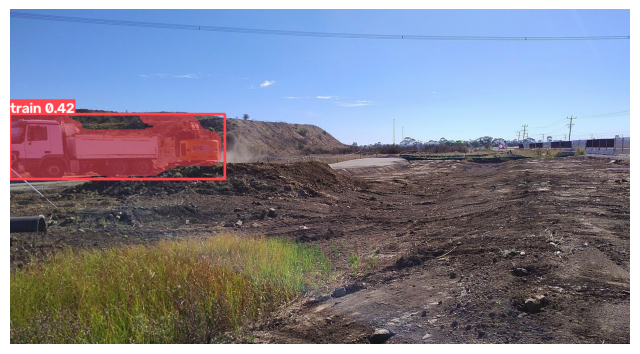

1 máscaras no canteiro


In [3]:
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd
from ultralytics import YOLO
from ultralytics.utils import DATASETS_DIR

model = YOLO("yolov8n-seg.pt")
treino = model.train(
    data="coco8-seg.yaml", epochs=3, imgsz=320, batch=4,
    project="runs", name="coco8seg", exist_ok=True, plots=False, verbose=False,
)
pasta = Path(treino.save_dir)
df = pd.read_csv(pasta / "results.csv")
df.columns = df.columns.str.strip()
melhor = YOLO(pasta / "weights" / "best.pt")

print(df[["epoch", "train/box_loss", "train/seg_loss", "metrics/mAP50(M)"]].to_string(index=False))
r = melhor("https://raw.githubusercontent.com/naubergois/curso-segmentacao-colab/main/midia/canteiro.jpg", verbose=False)[0]
plt.figure(figsize=(8, 4.5))
plt.imshow(r.plot()[:, :, ::-1])
plt.axis("off")
plt.show()
print(0 if r.masks is None else len(r.masks), "máscaras no canteiro")

In [4]:
# @title Correção automática (rode, não precisa ler)
from collections import Counter
from functools import lru_cache

_raiz = DATASETS_DIR / "coco8-seg"
_arquivos = sorted((_raiz / "labels" / "train").glob("*.txt"))
_linhas = [l.split() for f in _arquivos for l in f.read_text().splitlines() if l.strip()]
_por_classe = Counter(int(l[0]) for l in _linhas)


def _pontos():
    nums = _arquivos[0].read_text().splitlines()[0].split()
    return (len(nums) - 1) // 2


@lru_cache(None)
def _map50_mascara():
    return float(melhor.val(data="coco8-seg.yaml", imgsz=320, verbose=False, plots=False).seg.map50)


VERIFICAR = {
    1: lambda r: int(r) == len(list((_raiz / "images" / "train").glob("*.jpg"))),
    2: lambda r: int(r) == len(_linhas),
    3: lambda r: r in {model.names[c] for c, n in _por_classe.items() if n == max(_por_classe.values())},
    4: lambda r: int(r) == _pontos(),
    5: lambda r: int(r) == int(df.loc[df["train/seg_loss"].idxmin(), "epoch"]),
    6: lambda r: abs(float(r) - _map50_mascara()) < 1e-3,
}

_acertos = {}


def conferir(n, resposta):
    if resposta is None:
        print(f"Exercício {n}: ainda sem resposta.")
        return
    try:
        certo = bool(VERIFICAR[n](resposta))
    except Exception as erro:
        certo = False
        print(f"  (a verificação deu erro: {erro})")
    _acertos[n] = certo
    print(f"Exercício {n}: " + ("✅ certo!" if certo else "❌ ainda não. Releia o enunciado e tente de novo."))


def placar():
    print(f"{sum(_acertos.values())} de {len(VERIFICAR)} exercícios certos.")

## Sua vez

Abra o primeiro `.txt` de treino, em ordem alfabética. Quantos pontos tem o polígono da primeira linha? A classe é o primeiro número; cada ponto usa dois números.

*Dica:* (quantidade de números - 1) / 2.

Troque o `None` pela sua resposta e rode a célula.

In [5]:
resposta = None

conferir(4, resposta)

Exercício 4: ainda sem resposta.


## Uma solução

Compare com o que você fez. Existem outros caminhos certos: o que vale é a `conferir` aprovar.

In [6]:
arquivo = sorted((DATASETS_DIR / "coco8-seg" / "labels" / "train").glob("*.txt"))[0]
nums = arquivo.read_text().splitlines()[0].split()
resposta = (len(nums) - 1) // 2

conferir(4, resposta)

Exercício 4: ✅ certo!


## O que fica

Próximo: [Aula 4, exercício 5: A menor perda](https://colab.research.google.com/github/naubergois/curso-segmentacao-colab/blob/main/exercicios/aula4-exercicio5-a-menor-perda.ipynb).